# **Week 6: Applied Computer Vision in My Own Domain**
## **Recycling Waste Sorting (12-Class Garbage Classification) with ResNet-18**

| | |
|---|---|
| **Student** | Muhammad Luqman Khan |
| **Subject** | Introduction to Applied AI |

In [39]:
# ============ CHANGE ONLY THIS CELL FOR YOUR OWN DATASET ============
import os

def find_root(marker='cardboard'):
    """Find the folder that directly contains the class folders."""
    for root, dirs, files in os.walk('/kaggle/input'):
        if marker in dirs:
            return root
    raise FileNotFoundError('Class folders not found: check the Input panel')

DATA_ROOT = find_root()
TRAIN_DIR = DATA_ROOT          # one subfolder per class
TEST_DIR = None                # no test folder: the code carves a grouped test set
GRAYSCALE = False              # colour photos
IMG_SIZE = 224
BACKBONE = 'resnet18'
GROUP_PATTERN = None           # file names carry no subject id (confirmed in Part 1)
POSITIVE = None                # not a binary task
TARGET_RECALL = None           # not a binary task
print('DATA_ROOT =', DATA_ROOT)
# ====================================================================

DATA_ROOT = /kaggle/input/datasets/mostafaabla/garbage-classification/garbage_classification


In [40]:
import re
import time
import copy
import hashlib
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import transforms, models
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score,
                             roc_auc_score, roc_curve)

torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cuda


In [41]:
def index_folder(folder):
    """One row per image: path, class label, file name, group id."""
    rows = []
    for cls in sorted(os.listdir(folder)):
        cdir = os.path.join(folder, cls)
        if not os.path.isdir(cdir):
            continue
        for f in sorted(os.listdir(cdir)):
            if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.tif')):
                rows.append({'path': os.path.join(cdir, f), 'label': cls,
                             'file': f})
    df = pd.DataFrame(rows)
    if GROUP_PATTERN:
        m = df['file'].str.extract(GROUP_PATTERN, expand=False)
        df['group'] = m.fillna(df['file'])
    else:
        df['group'] = df['file']
    return df

train_df = index_folder(TRAIN_DIR)
test_df = index_folder(TEST_DIR) if TEST_DIR else None
classes = sorted(train_df['label'].unique())

counts = train_df['label'].value_counts().reindex(classes)
print(counts.to_string())
print(f'Imbalance ratio (max / min): {counts.max() / counts.min():.1f}')
print(f'Images per group: {len(train_df) / train_df.group.nunique():.2f}')
print('Total images:', len(train_df), '| classes:', len(classes))
print(train_df['file'].sample(8, random_state=0).tolist())

label
battery         945
biological      985
brown-glass     607
cardboard       891
clothes        5325
green-glass     629
metal           769
paper          1050
plastic         865
shoes          1977
trash           697
white-glass     775
Imbalance ratio (max / min): 8.8
Images per group: 1.00
Total images: 15515 | classes: 12
['clothes193.jpg', 'clothes4934.jpg', 'metal618.jpg', 'clothes2660.jpg', 'battery25.jpg', 'brown-glass169.jpg', 'biological265.jpg', 'biological271.jpg']


         w      h
min  156.0  152.0
50%  400.0  384.0
max  865.0  712.0
Colour modes: {'RGB': 298, 'P': 2}


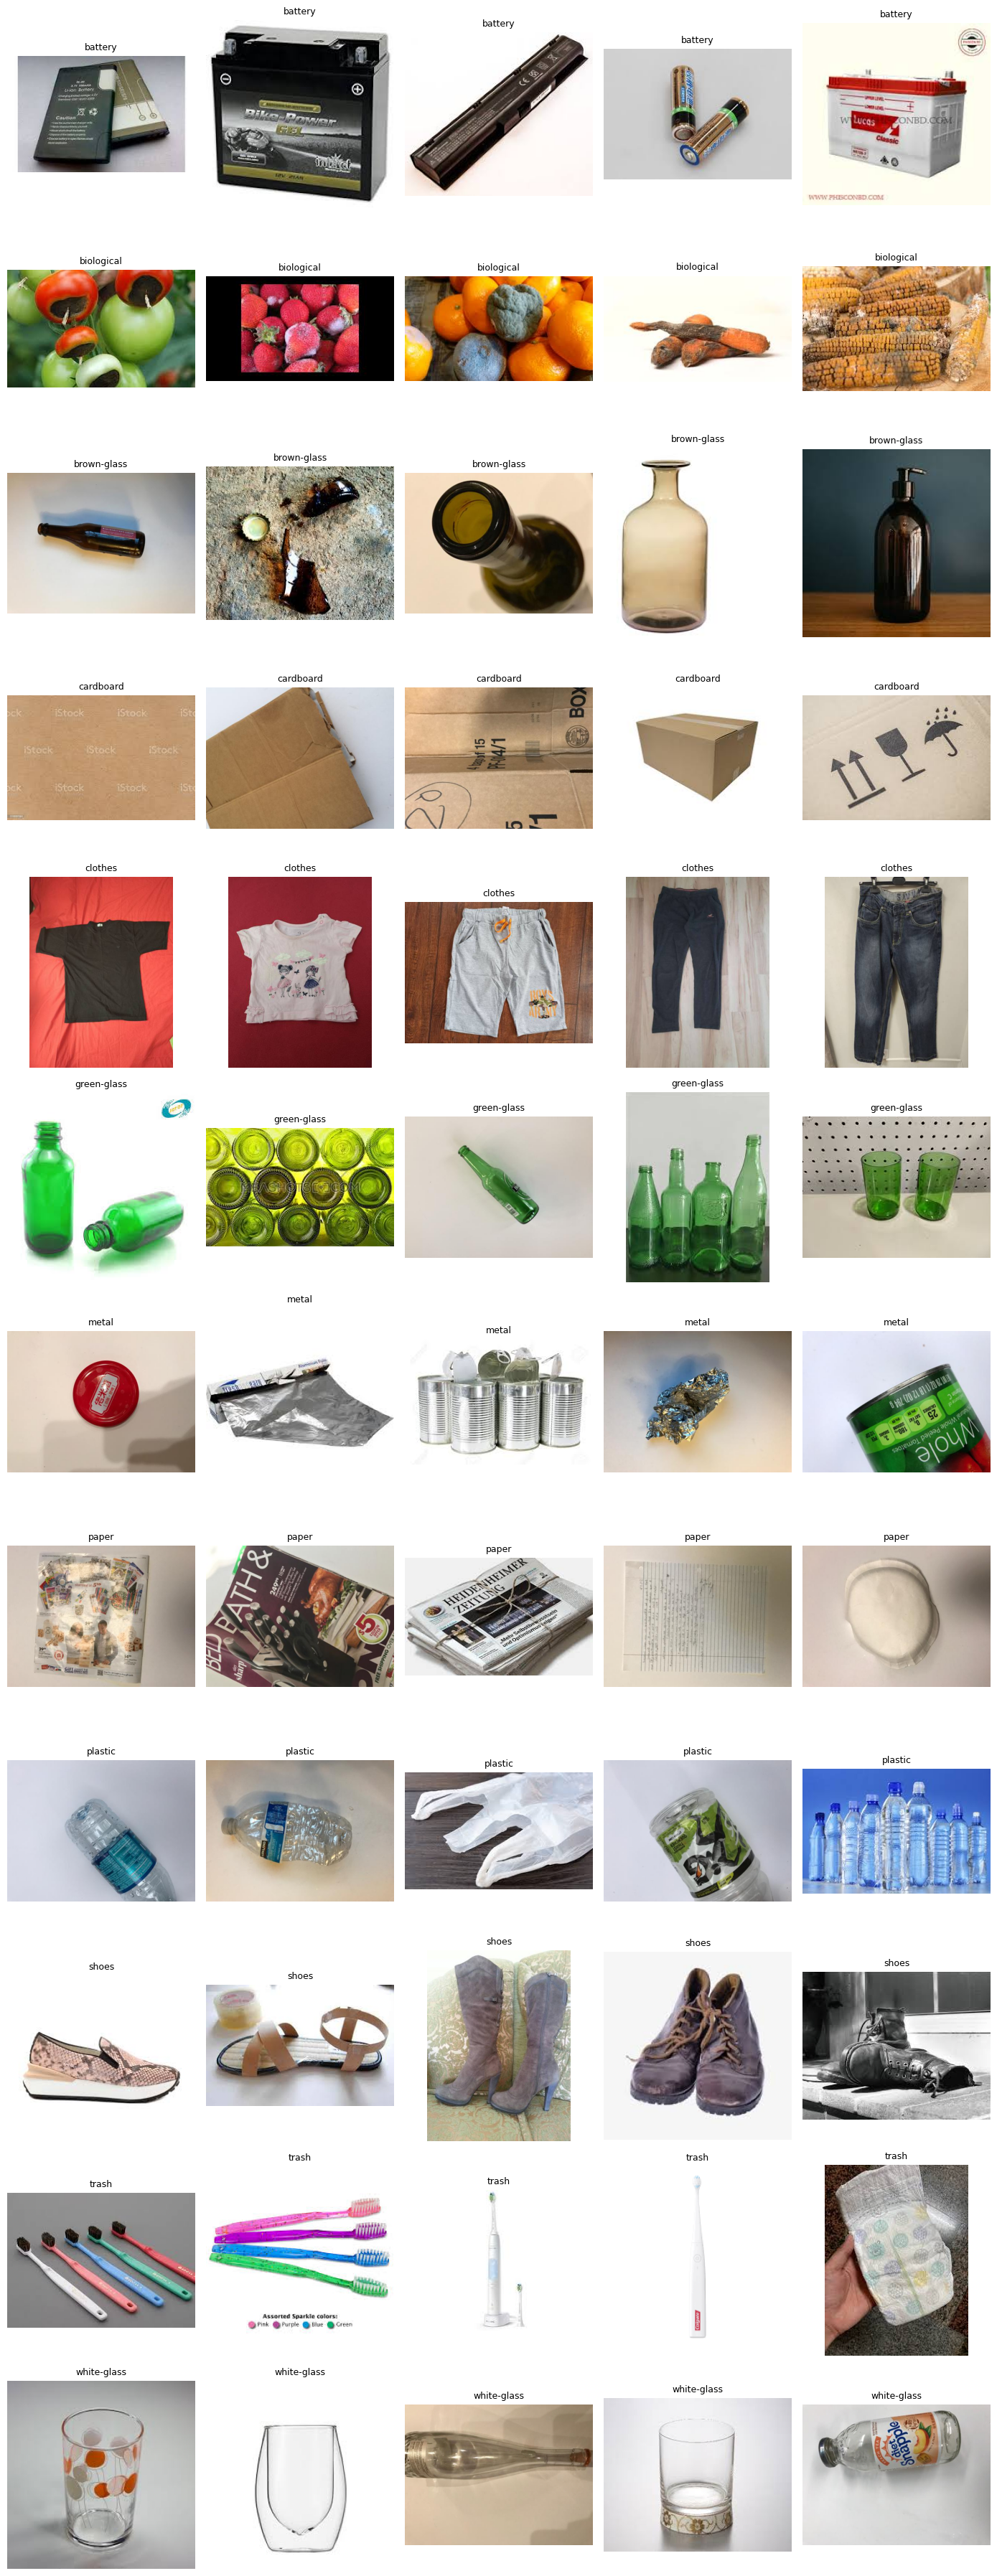

In [42]:
sample = train_df.sample(min(300, len(train_df)), random_state=0)
info = []
for p in sample['path']:
    with Image.open(p) as im:
        info.append({'w': im.size[0], 'h': im.size[1], 'mode': im.mode})
info = pd.DataFrame(info)
print(info.describe().round(0).loc[['min', '50%', 'max']])
print('Colour modes:', info['mode'].value_counts().to_dict())

fig, axes = plt.subplots(len(classes), 5, figsize=(14, 3 * len(classes)))
axes = np.atleast_2d(axes)
for r, c in enumerate(classes):
    paths = train_df[train_df.label == c]['path'].sample(5, random_state=1)
    for ax, p in zip(axes[r], paths):
        ax.imshow(Image.open(p).convert('RGB'))
        ax.set_title(c, fontsize=9)
        ax.axis('off')
plt.tight_layout()
plt.show()

## **Part 1: Indexing and Auditing the Dataset**

### **1. Dataset Overview**
I am using the **Garbage Classification** dataset (Kaggle, by mostafaabla). After indexing every image into one table (path, class label, file name, group id), I found **15,515 images across 12 classes**: battery, biological, brown-glass, cardboard, clothes, green-glass, metal, paper, plastic, shoes, trash and white-glass.

### **2. Class Counts and Imbalance**
| Class | Images | Class | Images |
|---|---|---|---|
| battery | 945 | plastic | 865 |
| biological | 985 | shoes | 1,977 |
| brown-glass | 607 | trash | 697 |
| cardboard | 891 | white-glass | 775 |
| clothes | 5,325 | metal | 769 |
| green-glass | 629 | paper | 1,050 |

The largest class is **clothes (5,325)** and the smallest is **brown-glass (607)**, so the **imbalance ratio is 5,325 / 607 = 8.8**. Clothes alone makes up about **34%** of the dataset, and shoes adds another **13%**. Most other classes have only 600 to 1,050 images.

**Why this matters:** a lazy model that leans toward clothes and shoes could still post a high accuracy while failing on the small classes such as brown-glass and green-glass. For this reason I will handle imbalance with class weights (or a balanced sampler) and select the best model by **macro-F1**, which treats every class equally, rather than by accuracy.

### **3. Image Properties**
The images are **colour photographs**. In a random sample of 300 images, **298 were RGB** and **2 were palette ("P") mode**, which the loader converts to RGB. Image sizes vary widely, from about **156 × 152** pixels up to **865 × 712**, with a typical (median) size of **400 × 384**. Because sizes differ, every image will be resized to **224 × 224** for the network. I set `GRAYSCALE = False` since colour carries real information in this task, for example separating brown, green and white glass.

### **4. Group Information**
The file names (such as `clothes193.jpg` or `metal618.jpg`) contain only the class name and a running number, with **no patient, plant or part id**. This gives **1.00 images per group**, meaning every image is currently its own group. I will address this limitation in Part 2 by grouping near-duplicate images together.

### **5. First Shortcut Suspect**
In the sample grid, the **background and photo style** look different from class to class. Clothes and shoes often appear on clean, plain backgrounds, while classes such as trash, paper and biological tend to appear in messier, real-world scenes. This is **not the garbage itself**, so the model could learn "plain background means clothes" instead of learning the object. I will test this with **Grad-CAM in Part 6** to see whether the model looks at the object or the background.

In [ ]:
from concurrent.futures import ThreadPoolExecutor

def md5(path):
    with open(path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()

def fingerprint(path, n=32):
    with Image.open(path) as im:
        im.draft('L', (n * 4, n * 4))
        a = np.asarray(im.convert('L').resize((n, n)), dtype=np.float32)
    return ((a - a.mean()) / (a.std() + 1e-6)).flatten()

train_df = index_folder(TRAIN_DIR)
all_df = train_df
with ThreadPoolExecutor(16) as ex:
    all_df['md5'] = list(ex.map(md5, all_df['path']))
exact = all_df[all_df.duplicated('md5', keep=False)]
print('Total images:', len(all_df))
print('Exact duplicate files:', len(exact))

Exact duplicate files: 37
Extra copies (removable): 19
Duplicate sets with different class labels: 3
Duplicate sets per class:
label
green-glass    14
plastic         2
clothes         1
metal           1


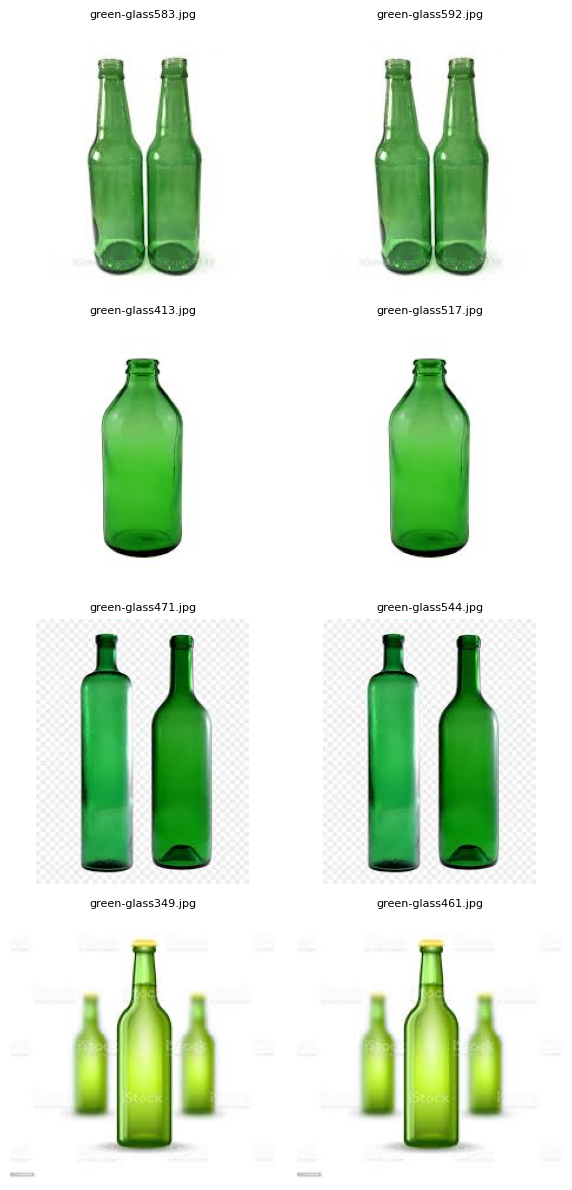

In [44]:
# Exact duplicates: details + visual check
extra = all_df.duplicated('md5').sum()
cross = (exact.groupby('md5')['label'].nunique() > 1).sum()
print('Exact duplicate files:', len(exact))
print('Extra copies (removable):', extra)
print('Duplicate sets with different class labels:', cross)
print('Duplicate sets per class:')
print(exact.drop_duplicates('md5')['label'].value_counts().to_string())

# Show up to 4 duplicate sets side by side
sets = exact.groupby('md5')['path'].apply(list).tolist()[:4]
fig, axes = plt.subplots(len(sets), 2, figsize=(6, 3 * len(sets)))
axes = np.atleast_2d(axes)
for r, paths in enumerate(sets):
    for k in range(2):
        axes[r, k].imshow(Image.open(paths[k]).convert('RGB'))
        axes[r, k].set_title(os.path.basename(paths[k]), fontsize=8)
        axes[r, k].axis('off')
plt.tight_layout()
plt.show()

             label                file
9781         metal        metal459.jpg
15088  white-glass  white-glass412.jpg
11708      plastic      plastic556.jpg
15475  white-glass  white-glass761.jpg
11267      plastic      plastic159.jpg
14773  white-glass  white-glass129.jpg


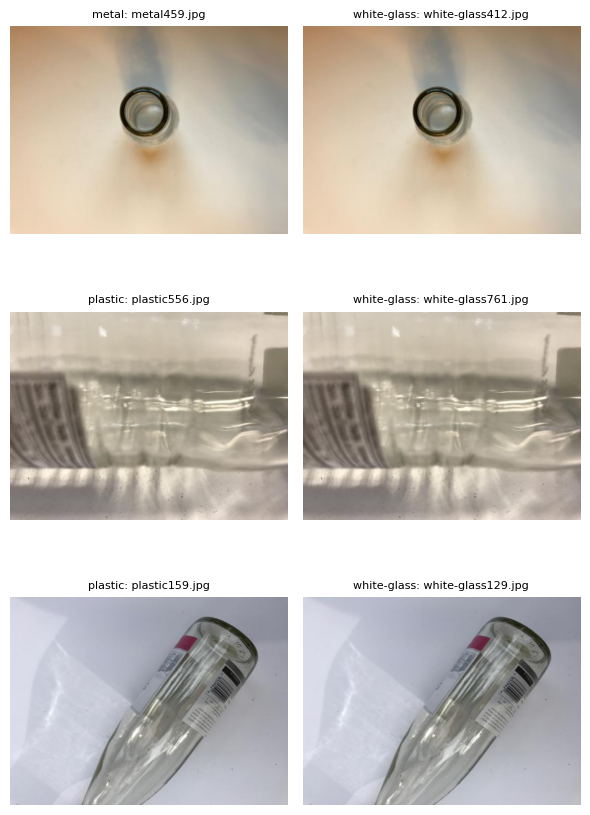

In [45]:
conf = exact.groupby('md5').filter(lambda g: g['label'].nunique() > 1)
sets = conf.groupby('md5')['path'].apply(list).tolist()
print(conf.sort_values('md5')[['label', 'file']].to_string())

fig, axes = plt.subplots(len(sets), 2, figsize=(6, 3 * len(sets)))
axes = np.atleast_2d(axes)
for r, paths in enumerate(sets):
    for k in range(2):
        axes[r, k].imshow(Image.open(paths[k]).convert('RGB'))
        axes[r, k].set_title(f"{os.path.basename(os.path.dirname(paths[k]))}: "
                             f"{os.path.basename(paths[k])}", fontsize=8)
        axes[r, k].axis('off')
plt.tight_layout()
plt.show()

In [46]:
conf_md5 = exact.groupby('md5')['label'].nunique()
conf_md5 = set(conf_md5[conf_md5 > 1].index)

before = len(train_df)
train_df = train_df[~train_df['md5'].isin(conf_md5)]           # drop conflicting sets
train_df = train_df.drop_duplicates('md5', keep='first')       # keep 1 copy of the rest
train_df = train_df.reset_index(drop=True)
all_df = train_df                                              # keep them in sync
print(f'Removed {before - len(train_df)} images | now {len(train_df)} left')
print('Exact duplicates remaining:', train_df.duplicated('md5').sum())
print(train_df['label'].value_counts().reindex(classes).to_string())

Removed 22 images | now 15493 left
Exact duplicates remaining: 0
label
battery         945
biological      985
brown-glass     607
cardboard       891
clothes        5324
green-glass     614
metal           768
paper          1050
plastic         863
shoes          1977
trash           697
white-glass     772


In [47]:
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

# keep train_df and all_df as the same, cleanly indexed table
train_df = train_df.reset_index(drop=True)
all_df = train_df

with ThreadPoolExecutor(max_workers=16) as ex:
    T = np.stack(list(tqdm(ex.map(fingerprint, all_df['path']),
                           total=len(all_df)))).astype(np.float32)
Tt = torch.tensor(T, device=device)
n = len(Tt)

found = []
for s in range(0, n, 256):
    d = torch.cdist(Tt[s:s + 256], Tt, p=1) / Tt.shape[1]   # mean abs difference
    ii, jj = torch.where(d < 0.10)                          # lab threshold
    keep = (ii + s) < jj                                    # each pair once
    ii, jj = ii[keep], jj[keep]
    found += list(zip((ii + s).tolist(), jj.tolist(), d[ii, jj].tolist()))

pairs_df = pd.DataFrame(found, columns=['i', 'j', 'dist'])
pairs_df['label_i'] = all_df['label'].values[pairs_df['i']]
pairs_df['label_j'] = all_df['label'].values[pairs_df['j']]
print('Near-duplicate pairs:', len(pairs_df))
print('Images involved:', len(set(pairs_df.i) | set(pairs_df.j)))
print('Pairs with different class labels:',
      (pairs_df.label_i != pairs_df.label_j).sum())
print('Closest distances:', np.sort(pairs_df.dist.values)[:5].round(3))

# Near-duplicate clusters become the groups for the split
g = coo_matrix((np.ones(len(pairs_df)), (pairs_df.i, pairs_df.j)), shape=(n, n))
n_groups, comp = connected_components(g, directed=False)
train_df['group'] = [f'g{c}' for c in comp]
print('Groups:', n_groups,
      '| images per group:', round(len(train_df) / n_groups, 2))

  0%|          | 0/15493 [00:00<?, ?it/s]

Near-duplicate pairs: 100
Images involved: 184
Pairs with different class labels: 4
Closest distances: [0.001 0.001 0.003 0.003 0.004]
Groups: 15397 | images per group: 1.01


        label_i      label_j   dist
14  brown-glass  green-glass  0.080
16  brown-glass  green-glass  0.039
17  brown-glass  green-glass  0.086
18  brown-glass  green-glass  0.072
52        paper        paper  0.099
28  green-glass  green-glass  0.099


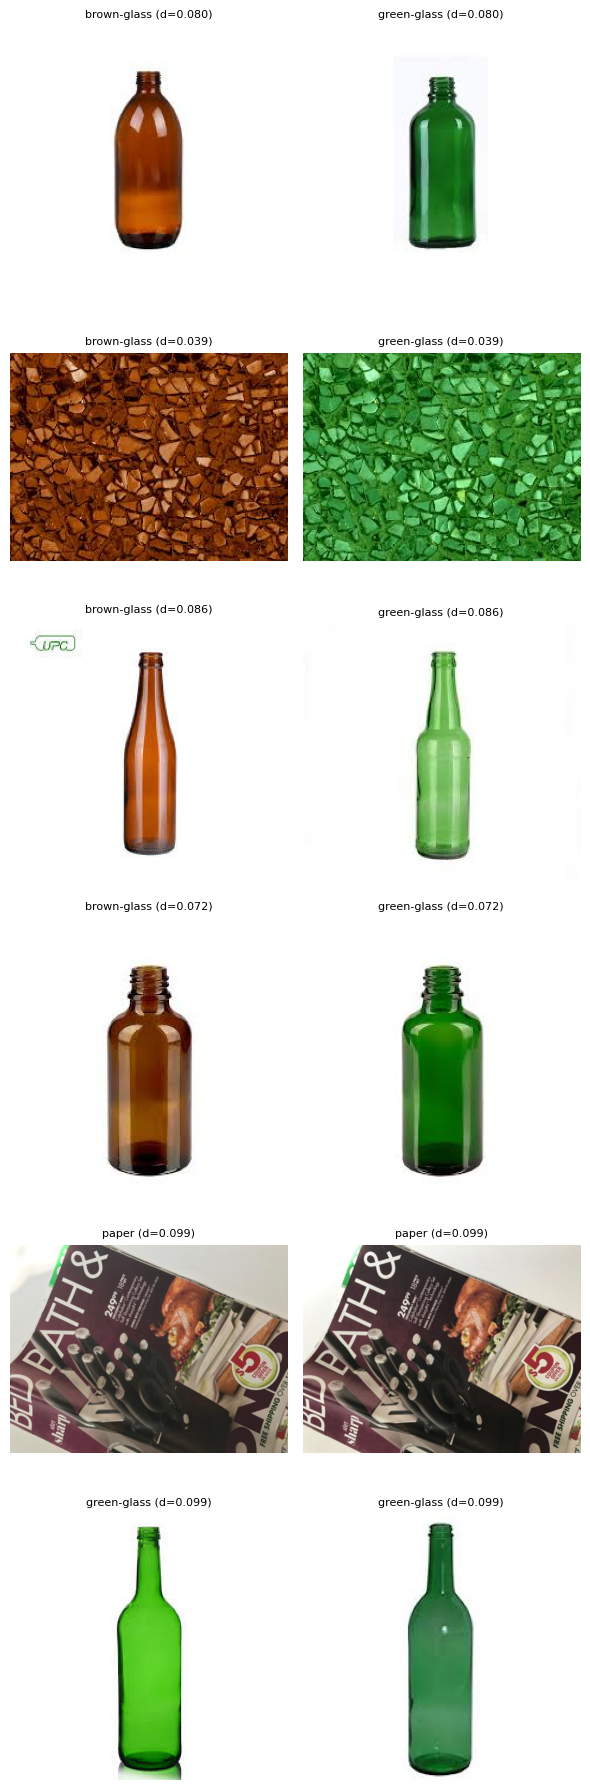

In [48]:
cross_pairs = pairs_df[pairs_df.label_i != pairs_df.label_j]
far_pairs = pairs_df.sort_values('dist', ascending=False).head(2)
show = pd.concat([cross_pairs, far_pairs]).drop_duplicates(['i', 'j'])
print(show[['label_i', 'label_j', 'dist']].round(3).to_string())

fig, axes = plt.subplots(len(show), 2, figsize=(6, 3 * len(show)))
axes = np.atleast_2d(axes)
for r, (_, row) in enumerate(show.iterrows()):
    for k, idx in enumerate([int(row.i), int(row.j)]):
        axes[r, k].imshow(Image.open(all_df.path.iloc[idx]).convert('RGB'))
        axes[r, k].set_title(f"{all_df.label.iloc[idx]} (d={row.dist:.3f})",
                             fontsize=8)
        axes[r, k].axis('off')
plt.tight_layout()
plt.show()

In [49]:
# Validation split BY GROUP: no patient appears in both train and val
sgkf = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=42)
tr_idx, va_idx = next(sgkf.split(train_df, train_df['label'],
                                 train_df['group']))
tr_df = train_df.iloc[tr_idx].reset_index(drop=True)
va_df = train_df.iloc[va_idx].reset_index(drop=True)
if not TEST_DIR:                                       # carve a grouped test set
    tr_idx, te_idx = next(sgkf.split(tr_df, tr_df['label'], tr_df['group']))
    tr_df, test_df = (tr_df.iloc[tr_idx].reset_index(drop=True),
                      tr_df.iloc[te_idx].reset_index(drop=True))

shared = set(tr_df.group) & set(va_df.group)
print(f'train {len(tr_df)} | val {len(va_df)} | test {len(test_df)}')
print('Groups shared by train and val:', len(shared))   # must be 0
print(va_df['label'].value_counts().to_string())

train 10756 | val 2579 | test 2158
Groups shared by train and val: 0
label
clothes        879
shoes          325
biological     181
paper          170
battery        160
cardboard      150
plastic        141
metal          125
white-glass    124
trash          117
brown-glass    105
green-glass    102


In [50]:
split_of = {}
for name, d in [('train', tr_df), ('val', va_df), ('test', test_df)]:
    for p in d.path:
        split_of[p] = name

paths = all_df.path.values
grouped_cross = sum(split_of[paths[i]] != split_of[paths[j]]
                    for i, j in zip(pairs_df.i, pairs_df.j))

rng = np.random.default_rng(0)                          # a random 70/15/15 split
rand = rng.choice(['train', 'val', 'test'], size=len(paths), p=[0.7, 0.15, 0.15])
random_cross = sum(rand[i] != rand[j] for i, j in zip(pairs_df.i, pairs_df.j))

print('Near-duplicate pairs split across sets, GROUPED split:', grouped_cross)
print('Near-duplicate pairs split across sets, RANDOM split :', random_cross)

Near-duplicate pairs split across sets, GROUPED split: 0
Near-duplicate pairs split across sets, RANDOM split : 39


## **Part 2: Leakage Audit**

### **1. Exact Duplicates**
An MD5 check found **37 files that belong to duplicate sets**. These form **18 sets**, which means **19 extra copies**. The duplicates are concentrated in one class: **14 of the 18 sets are green-glass**, with the other four in plastic (2), clothes (1) and metal (1). All of them are inside the training folder, because this dataset has no separate test set.

**Label conflicts:** **3 of the 18 sets** had the *same image filed under two different classes*: metal459 and white-glass412, plastic556 and white-glass761, and plastic159 and white-glass129. A model cannot be right for both labels, so at least one label in each pair is wrong.

**What I did:** I kept one copy of every ordinary duplicate set. For the 3 conflicting sets I removed **both** files, since the true label is uncertain. In total **22 images were removed**, leaving **15,493**.

### **2. Near-Duplicates**
The lab's near-duplicate check compares test images against train images, but this dataset has no test folder. So I ran the same fingerprint check (32 × 32 standardized thumbnail, threshold 0.10) **across the whole dataset**. It found **100 near-duplicate pairs involving 184 images**, about 1% of the data. The closest distances were 0.001 to 0.004, well below the lab's recompression score of 0.007, so those are almost certainly the same photo.

**Pairs I inspected before deleting anything:**
- **4 brown-glass vs green-glass pairs (d = 0.039 to 0.086):** the same bottle shape, and in one case the same broken-glass texture, **recoloured**. The fingerprint is grayscale, so it cannot see colour. These are *not* true duplicates, and the labels are correct because colour is exactly what separates these classes.
- **1 paper vs paper pair (d = 0.099):** the same magazine photo, slightly cropped. A **real near-duplicate**.
- **1 green-glass vs green-glass pair (d = 0.099):** two different bottles of similar shape, a **look-alike false alarm**.

**What I did:** I **deleted none** of the near-duplicates. Instead I turned each cluster into a *group*, so every cluster stays on one side of the split. This is harmless for look-alikes and protective for real copies.

### **3. Group Split**
The file names (for example `metal618.jpg`) carry no patient, plant or part id, so the dataset started with **1.00 images per group**. After grouping the near-duplicate clusters, there are **15,397 groups for 15,493 images (1.01 images per group)**.

I split with a stratified group split: **train 10,756 | validation 2,579 | test 2,158**. The printed number of groups shared by train and validation is **0**. Every class appears in validation, from clothes (879) down to green-glass (102).

### **4. Grouped vs Random Split**
As a check, I counted how many near-duplicate pairs end up on different sides. My **grouped split separated 0 pairs**, while a **random 70/15/15 split would have separated 39**.

**What would have happened with a random split:** about 39 test or validation images would have had a near-copy in the training set, so the model could be scored on pictures it had effectively already seen. That would **inflate the test score** by rewarding memory instead of real recognition, and the true performance on new garbage photos would be lower.

### **5. Honest Limitations**
Because the file names have no subject id, my groups only cover duplicates that the fingerprint can find. Copies that were heavily edited, or photos of the same object taken from different angles, could still be shared between splits. The test score should therefore be read as slightly optimistic.

### **6. Problems I Faced and What I Did Instead**

**Problem 1: the lab's near-duplicate check did not run.** The lab code only compares test images against train images, and it sits inside `if TEST_DIR:`. My dataset has no test folder (`TEST_DIR = None`), so that block was silently skipped.
**What I did instead:** I wrote an all-versus-all comparison on the GPU, with the same fingerprint and the same 0.10 threshold, and used the resulting clusters as group ids.

**Problem 2: no group id in the file names.** With `GROUP_PATTERN = None`, every image was its own group, so the "0 shared groups" check would have passed trivially and proven nothing.
**What I did instead:** I built the groups from near-duplicate clusters, so the check now has real meaning.

**Problem 3: the duplicate-check cell hung.** The MD5 cell ran for a very long time with no output, because it reads 15,515 small files one at a time from slow network storage.
**What I did instead:** I read the files in parallel with a thread pool and added a progress bar. The same step then finished in **about 7 seconds**, with the same result.

The **lab's MD5 loop** was replaced by a thread pool. It gives the same hashes and the same **result: 37 duplicate** files.

**Problem 4: `NameError: name 'train_df' is not defined`.** The notebook session had restarted, which wiped every variable from memory.
**What I did instead:** I re-ran the configuration, imports and indexing cell to rebuild `train_df`, and then continued.

**Problem 5: false alarms from the grayscale fingerprint.** It flagged brown and green bottles as near-duplicates, because it cannot see colour.
**What I did instead:** I looked at the flagged pairs before deleting anything, and kept the colour-different pairs. Their labels are correct, and grouping them is harmless.


In [51]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
to_rgb = [transforms.Grayscale(num_output_channels=3)] if GRAYSCALE else []

train_tf = transforms.Compose(to_rgb + [
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose(to_rgb + [
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class ImageTable(Dataset):
    def __init__(self, df, tf):
        self.paths = df['path'].tolist()
        self.y = df['label'].map({c: i for i, c in enumerate(classes)}).tolist()
        self.tf = tf
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i])
        img = img.convert('L' if GRAYSCALE else 'RGB')
        return self.tf(img), self.y[i]

train_ds = ImageTable(tr_df, train_tf)
val_ds = ImageTable(va_df, eval_tf)
test_ds = ImageTable(test_df, eval_tf)

In [52]:
n_c = np.bincount(train_ds.y, minlength=len(classes))
class_w = len(train_ds) / (len(classes) * n_c)        # N / (K * n_c)
print(dict(zip(classes, class_w.round(3))))
print('n_c:', dict(zip(classes, n_c)))
print('N =', len(train_ds), '| K =', len(classes))
loss_w = torch.tensor(class_w, dtype=torch.float32, device=device)

USE_SAMPLER = False     # try True: balanced batches instead of weighted loss
if USE_SAMPLER:
    sample_w = class_w[train_ds.y]                    # P(i) ~ 1 / n_class(i)
    sampler = WeightedRandomSampler(sample_w, len(sample_w), replacement=True)
    train_dl = DataLoader(train_ds, 32, sampler=sampler, num_workers=2)
    loss_w = None
else:
    train_dl = DataLoader(train_ds, 32, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, 64, num_workers=2)
test_dl = DataLoader(test_ds, 64, num_workers=2)

{'battery': np.float64(1.36), 'biological': np.float64(1.326), 'brown-glass': np.float64(2.134), 'cardboard': np.float64(1.457), 'clothes': np.float64(0.242), 'green-glass': np.float64(2.114), 'metal': np.float64(1.679), 'paper': np.float64(1.215), 'plastic': np.float64(1.491), 'shoes': np.float64(0.655), 'trash': np.float64(1.867), 'white-glass': np.float64(1.654)}
n_c: {'battery': np.int64(659), 'biological': np.int64(676), 'brown-glass': np.int64(420), 'cardboard': np.int64(615), 'clothes': np.int64(3699), 'green-glass': np.int64(424), 'metal': np.int64(534), 'paper': np.int64(738), 'plastic': np.int64(601), 'shoes': np.int64(1368), 'trash': np.int64(480), 'white-glass': np.int64(542)}
N = 10756 | K = 12


## **Part 3: Transforms and Imbalance Handling**

### **1. Class Weights**
I used the formula **weight = N / (K × n_c)**, where N is the number of training images, K is the number of classes and n_c is the number of images in that class. For my training set, **N = 10,756** and **K = 12**.

**Worked example (brown-glass, the rarest class):**
n_c = 420, so weight = 10,756 / (12 × 420) = 10,756 / 5,040 = **2.134**

**Worked example (clothes, the biggest class):**
n_c = 3,699, so weight = 10,756 / (12 × 3,699) = 10,756 / 44,388 = **0.242**

| Class | Weight | Class | Weight |
|---|---|---|---|
| battery | 1.360 | plastic | 1.491 |
| biological | 1.326 | shoes | 0.655 |
| brown-glass | 2.134 | trash | 1.867 |
| cardboard | 1.457 | white-glass | 1.654 |
| clothes | 0.242 | metal | 1.679 |
| green-glass | 2.114 | paper | 1.215 |

**What this means:** a mistake on a brown-glass image costs the model about **2.134 / 0.242 = 8.8 times** more than a mistake on a clothes image. That ratio equals the imbalance ratio from Part 1, which is exactly what balanced weights should do. Both brown-glass and green-glass are weighted above 2, and clothes is weighted well below 1.

**Method chosen:** I used the **weighted loss** (`USE_SAMPLER = False`). The sampler option was not run.

### **2. Augmentations**
**Kept (all three from the lab):**
- **Random resized crop (scale 0.8 to 1.0):** objects in garbage photos are not always centred or at the same zoom, so mild cropping teaches the model to recognise an object at different framings.
- **Random rotation (10 degrees):** bottles, boxes and shoes are photographed at slightly different angles, and a small tilt is realistic.
- **Brightness and contrast jitter (0.15):** the photos come from different websites with different lighting, so a small change builds tolerance without altering the object.

**Deliberately avoided:** any **hue or saturation change**. Colour is the main clue that separates **brown, green and white glass**, so shifting it could turn one class into another. Brightness and contrast keep the colour identity intact, which is why I kept only those.

**Not added:** horizontal flips. The lab leaves them out, and I kept the lab's baseline. They would be safe for this domain, since a mirrored bottle is still a bottle, so I could test them in a later experiment.

**Validation and test data** are only resized and normalised, with no random changes, so every evaluation is repeatable.

In [53]:
def build_model(name, n_classes):
    if name == 'resnet18':
        m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, last = m, m.fc, m.layer4
    elif name == 'resnet50':
        m = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, last = m, m.fc, m.layer4
    elif name == 'efficientnet_b0':
        w = models.EfficientNet_B0_Weights.DEFAULT
        m = models.efficientnet_b0(weights=w)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, n_classes)
        body, head, last = m, m.classifier, m.features[-1]
    else:
        raise ValueError(name)
    for p in body.parameters():
        p.requires_grad = False
    for p in head.parameters():
        p.requires_grad = True
    return m.to(device), head, last

model, head, last_block = build_model(BACKBONE, len(classes))
print(BACKBONE, 'trainable:',
      sum(p.numel() for p in model.parameters() if p.requires_grad))

resnet18 trainable: 6156


In [54]:
def predict(model, loader):
    model.eval()
    probs, ys = [], []
    with torch.no_grad():
        for xb, yb in loader:
            probs.append(F.softmax(model(xb.to(device)), 1).cpu())
            ys.append(yb)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()

def fit(model, params, epochs, lr):
    opt = torch.optim.Adam(params, lr=lr)
    best, best_state = -1, None
    for ep in range(epochs):
        model.train()
        t0 = time.time()
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            loss = F.cross_entropy(model(xb), yb, weight=loss_w)
            opt.zero_grad()
            loss.backward()
            opt.step()
        p, y = predict(model, val_dl)
        macro = f1_score(y, p.argmax(1), average='macro')   # not accuracy
        if macro > best:
            best, best_state = macro, copy.deepcopy(model.state_dict())
        print(f'epoch {ep + 1}: val macro-F1 {macro:.3f} '
              f'({time.time() - t0:.0f}s)')
    model.load_state_dict(best_state)
    return best

print('Phase 1: head only')
fit(model, head.parameters(), epochs=2, lr=1e-3)
print('Phase 2: fine-tune the last block')
for p in last_block.parameters():
    p.requires_grad = True
fit(model, [{'params': last_block.parameters(), 'lr': 1e-4},
            {'params': head.parameters(), 'lr': 1e-3}], epochs=3, lr=1e-3)

Phase 1: head only
epoch 1: val macro-F1 0.854 (44s)
epoch 2: val macro-F1 0.872 (44s)
Phase 2: fine-tune the last block
epoch 1: val macro-F1 0.913 (43s)
epoch 2: val macro-F1 0.929 (44s)
epoch 3: val macro-F1 0.938 (44s)


0.9379112372241947

## **Part 4: Building and Training the Model**

### **1. Model Setup**
I used **ResNet-18 pretrained on ImageNet** and replaced its final layer with a new 12-class head. At the start, **only the new head was trainable (6,156 parameters)**, which is 512 × 12 weights plus 12 biases. The whole backbone was frozen, so the model started from features it had already learned (edges, textures, shapes) and only had to learn how to map them to my 12 garbage classes.

### **2. Two-Phase Training**
- **Phase 1 (head only, 2 epochs, learning rate 1e-3):** the backbone stays frozen and only the new classifier layer learns.
- **Phase 2 (fine-tuning, 3 epochs):** I also unfroze the **last block (layer4, about 8.4 million parameters)** with a gentler learning rate of 1e-4, while the head kept 1e-3. This lets the deepest features adapt to garbage photos without destroying what the earlier layers already know.

The best epoch in each phase was chosen by **validation macro-F1**, not accuracy. With an imbalance ratio of 8.8, a model that ignores the small classes could still reach high accuracy, but it cannot win on macro-F1.

### **3. Validation Macro-F1**
| Phase | Epoch | Val macro-F1 |
|---|---|---|
| Phase 1 (head only) | 1 | 0.854 |
| Phase 1 (head only) | 2 | **0.872** |
| Phase 2 (fine-tune) | 1 | 0.913 |
| Phase 2 (fine-tune) | 2 | 0.929|
| Phase 2 (fine-tune) | 3 | **0.938** |

**After phase 1 the best macro-F1 was 0.872, and after phase 2 it was 0.938.**

### **4. Did Fine-Tuning Help?**
**Yes, clearly.** Fine-tuning raised the best validation macro-F1 by about **0.066** (from 0.872 to 0.938). A frozen ImageNet backbone is good with general objects, but garbage photos need finer cues, such as the texture of glass versus plastic or the difference between cardboard and paper. Letting the last block adapt gave the model those cues.

The gains are also shrinking: phase 2 improved by +0.041 over phase 1, then +0.016, then +0.009. This suggests the model was starting to level off, although it had not fully stopped improving.

### **5. Time Per Epoch and What I Would Do With More Time**
Each epoch took about **43 to 44 seconds** on the Kaggle T4 GPU. The whole run (5 epochs) took roughly **3.7 minutes**.

With more time I would run **about 5 to 10 more epochs of phase 2** (an extra 4 to 7 minutes), and stop once validation macro-F1 no longer improves. I would also try the balanced sampler and compare its macro-F1 with the weighted loss. I would not tune anything on the test set.

### **6. Note on Honesty**
The validation set was used to **choose the best epoch**, so 0.938 is slightly optimistic. The real estimate comes from the test set, which I will use **once** in Part 5.

              precision    recall  f1-score   support

     battery      0.953     0.968     0.961       126
  biological      0.992     0.945     0.968       128
 brown-glass      0.851     0.902     0.876        82
   cardboard      0.944     0.944     0.944       126
     clothes      0.995     0.977     0.986       746
 green-glass      0.906     0.989     0.946        88
       metal      0.847     0.917     0.881       109
       paper      0.938     0.951     0.944       142
     plastic      0.871     0.893     0.882       121
       shoes      0.945     0.975     0.960       284
       trash      0.911     0.920     0.915       100
 white-glass      0.977     0.792     0.875       106

    accuracy                          0.949      2158
   macro avg      0.927     0.931     0.928      2158
weighted avg      0.951     0.949     0.949      2158

Macro-F1: 0.928


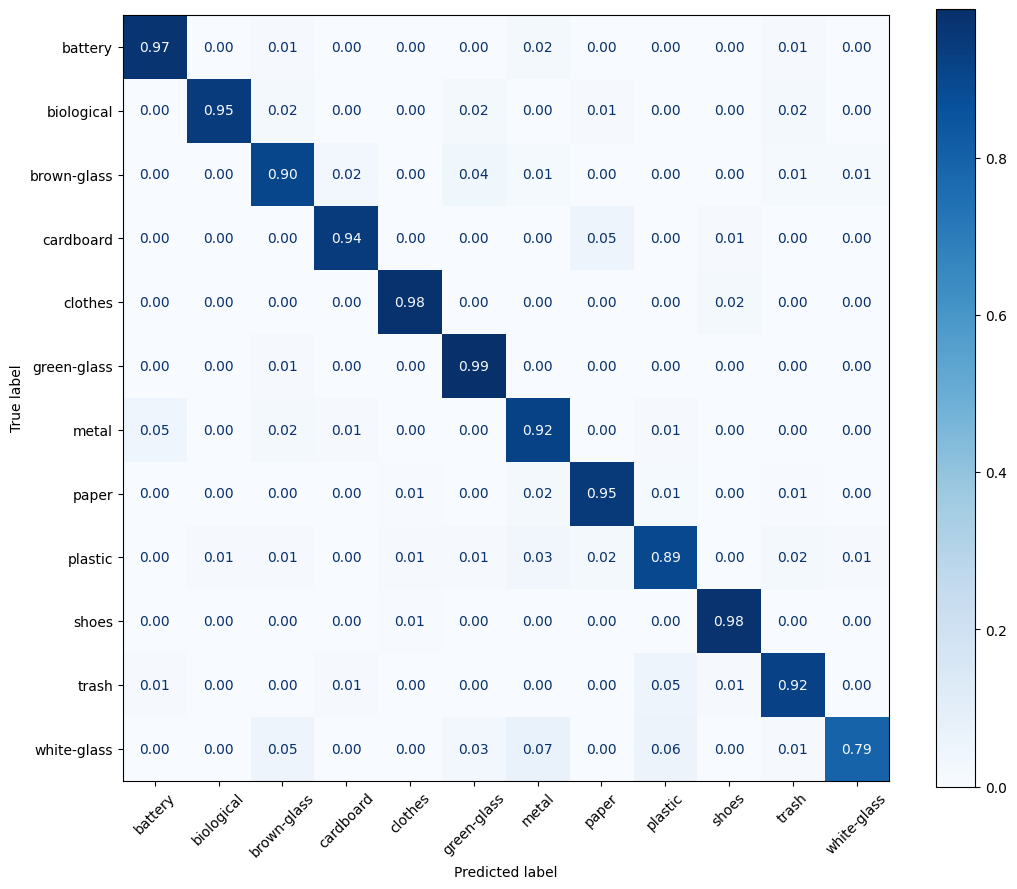

In [67]:
p_test, y_test = predict(model, test_dl)
pred = p_test.argmax(1)
print(classification_report(y_test, pred, target_names=classes, digits=3))
print('Macro-F1:', round(f1_score(y_test, pred, average='macro'), 3))

fig, ax = plt.subplots(figsize=(11, 9))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred, normalize='true'),
                       display_labels=classes).plot(
    cmap='Blues', ax=ax, xticks_rotation=45, values_format='.2f')
plt.tight_layout()
plt.show()

In [56]:
rep = classification_report(y_test, pred, target_names=classes, output_dict=True)
recall = {c: rep[c]['recall'] for c in classes}
print('Recall per class (lowest first):')
for c, r in sorted(recall.items(), key=lambda kv: kv[1]):
    print(f'  {c:12s} {r:.3f}')

cm = confusion_matrix(y_test, pred)
off = [(cm[i, j], classes[i], classes[j])
       for i in range(len(classes)) for j in range(len(classes)) if i != j]
print('\nTop confusions (count, true -> predicted):')
for k, t, p in sorted(off, reverse=True)[:5]:
    print(f'  {k:3d}  {t} -> {p}')

Recall per class (lowest first):
  white-glass  0.792
  plastic      0.893
  brown-glass  0.902
  metal        0.917
  trash        0.920
  cardboard    0.944
  biological   0.945
  paper        0.951
  battery      0.968
  shoes        0.975
  clothes      0.977
  green-glass  0.989

Top confusions (count, true -> predicted):
   14  clothes -> shoes
    7  white-glass -> metal
    6  white-glass -> plastic
    6  cardboard -> paper
    5  white-glass -> brown-glass


## **Part 5: Test Results (Used Once)**

### **1. Overall Performance**
I evaluated the model on the **2,158 held-out test images, one time only**, with no retraining afterwards. The results were **macro-F1 = 0.928**, **accuracy = 0.949** and weighted F1 = 0.949.

**Why macro-F1 is the headline number:** it is lower than accuracy because it gives every class equal weight. Accuracy is lifted by the two big classes, clothes (746 test images) and shoes (284), which the model handles very well (F1 0.986 and 0.960). Macro-F1 shows how the small classes are doing.

**Validation vs test:** validation macro-F1 was 0.938 and test macro-F1 is **0.928**. The gap is only 0.010, so choosing the best epoch on validation did not overfit it much.

### **2. Per-Class Results**
| Class | Precision | Recall | F1 | Test images |
|---|---|---|---|---|
| clothes | 0.995 | 0.977 | **0.986** | 746 |
| biological | 0.992 | 0.945 | 0.968 | 128 |
| battery | 0.953 | 0.968 | 0.961 | 126 |
| shoes | 0.945 | 0.975 | 0.960 | 284 |
| green-glass | 0.906 | 0.989 | 0.946 | 88 |
| cardboard | 0.944 | 0.944 | 0.944 | 126 |
| paper | 0.938 | 0.951 | 0.944 | 142 |
| trash | 0.911 | 0.920 | 0.915 | 100 |
| plastic | 0.871 | 0.893 | 0.882 | 121 |
| metal | 0.847 | 0.917 | 0.881 | 109 |
| brown-glass | 0.851 | 0.902 | 0.876 | 82 |
| white-glass | 0.977 | 0.792 | **0.875** | 106 |

### **3. Weakest Class: White-Glass**
**White-glass is the weakest class.** It has the lowest recall (**0.792**) and the lowest F1 (**0.875**). About **22 of the 106 white-glass test images were missed**, and **18 of those 22 went to just three classes: 7 were predicted as metal, 6 as plastic and 5 as brown-glass**. Its precision is high (0.977), so when the model says "white-glass" it is almost always right. It just says it too rarely.

**These missed images also explain the weak precision of other classes.** Metal has the lowest precision (**0.847**, about 18 wrong predictions), and 7 of them are white-glass. Plastic has precision 0.871 (about 16 wrong predictions), and 6 of them are white-glass and 5 are trash. Brown-glass has precision 0.851 (about 13 wrong predictions), and 5 are white-glass. Clear glass, clear plastic and shiny metal all share transparency and reflections, so they are naturally easy to mix up. This also matches Part 2, where the same image was filed under both white-glass and metal or plastic.

### **4. Top Confusions**
| Count | True class | Predicted as |
|---|---|---|
| 14 | clothes | shoes |
| 7 | white-glass | metal |
| 6 | white-glass | plastic |
| 6 | cardboard | paper |
| 5 | white-glass | brown-glass |

- **Clothes → shoes (14)** is the largest count, but clothes has 746 test images, so this is only about **1.9%** of the class. Many items look alike (a boot or jacket on a plain background), so it barely changes the clothes score.
- **Cardboard → paper (6)** is a natural pair: both are flat, brown-grey and fibrous.
- **White-glass → metal, plastic and brown-glass (18 in total)** are the mistakes that matter most, because they hurt a small class (about 100 images).
  
### **Note on the Confusion Matrix Figure**

**Problem:** the lab's default confusion matrix was hard to read. The 12 class names on the x-axis overlapped each other, the figure was small, and the colour scale was dominated by the clothes class (729 correct predictions). Because of that, the smaller classes looked pale and their mistakes were almost invisible.

**What I changed:** I kept the lab's `ConfusionMatrixDisplay` and changed only how it is drawn:
- `figsize=(11, 9)` makes the figure larger.
- `xticks_rotation=45` stops the class names from overlapping.
- `normalize='true'` divides each row by its class size, so every cell shows the **share of that true class** (its recall) instead of a raw count.

**What it shows:** the diagonal now reads as per-class recall, so every class has the same colour scale. White-glass stands out as the weakest row (about 0.79), and the main off-diagonal cells (white-glass → metal and plastic, clothes → shoes) are easy to spot. The raw counts are still reported above in the classification report (support column) and in the top-confusions table.

**Test-once rule:** this figure reuses the same `y_test` and `pred` from the single test run. No new prediction was made and nothing was tuned.
### **5. Binary Metrics Not Used**
My task has **12 classes, not two**, so the threshold-for-target-recall step, sensitivity/specificity and PPV do not apply. As the lab instructs, I analysed **per-class recall** instead.

### **6. Honest Limitations**
The test set was used once, and nothing was tuned on it. Even so, the near-duplicate check in Part 2 only catches copies the fingerprint can find, so the test score may be slightly optimistic. Some mislabelled images (like the 3 label conflicts I found) probably remain in the dataset, which puts a ceiling on the score of the most confusable classes.

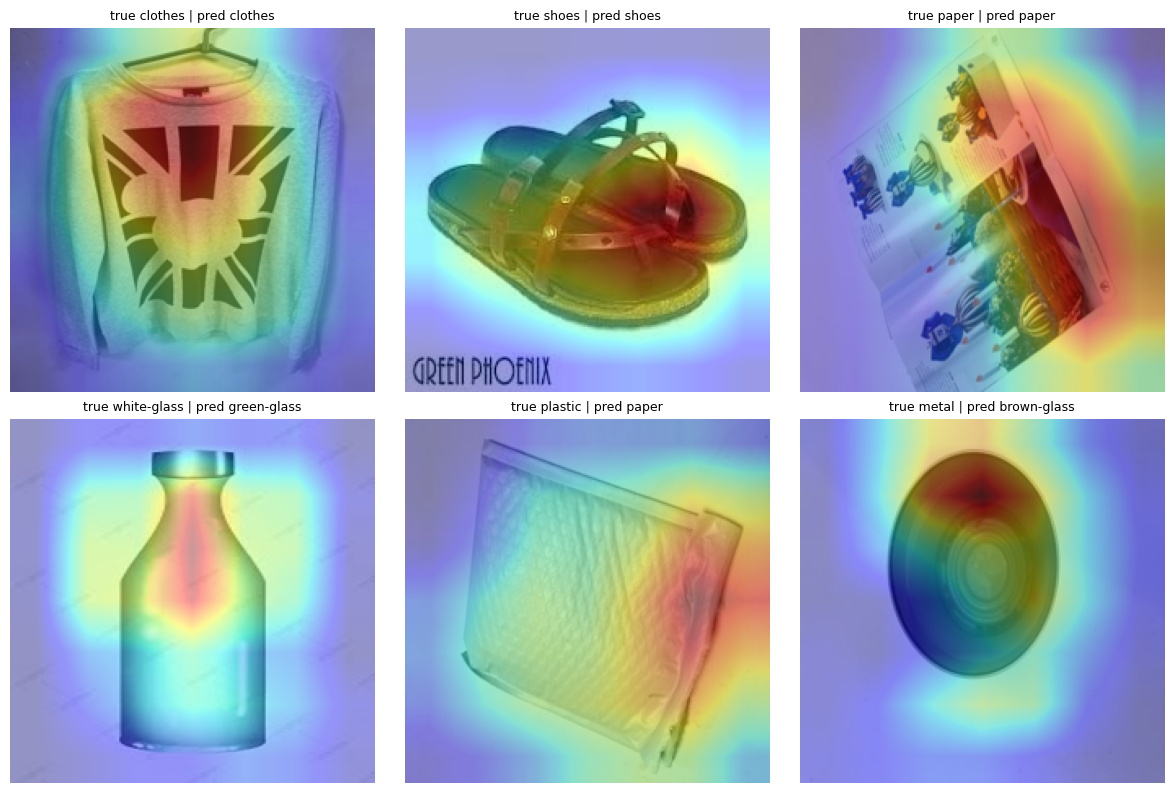

In [64]:
class GradCAM:
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        layer.register_forward_hook(self._save_act)
        layer.register_full_backward_hook(self._save_grad)
    def _save_act(self, m, i, o):
        self.acts = o.detach()
    def _save_grad(self, m, gi, go):
        self.grads = go[0].detach()
    def __call__(self, x, cls=None):
        self.model.eval()
        x = x.unsqueeze(0).to(device).requires_grad_(True)
        logits = self.model(x)
        cls = int(logits.argmax()) if cls is None else cls
        self.model.zero_grad()
        logits[0, cls].backward()
        alpha = self.grads.mean(dim=(2, 3), keepdim=True)     # (1/Z) sum dy/dA
        cam = F.relu((alpha * self.acts).sum(1)).squeeze()    # ReLU(sum a*A)
        cam = F.interpolate(cam[None, None], size=x.shape[-2:],
                            mode='bilinear').squeeze()
        return (cam / (cam.max() + 1e-8)).cpu().numpy(), cls

for p in model.parameters():
    p.requires_grad = True
cam = GradCAM(model, last_block)
rng = np.random.default_rng(0)

def pick(cls_name, correct):
    c = classes.index(cls_name)
    idx = np.where((y_test == c) & ((pred == y_test) == correct))[0]
    return int(rng.choice(idx))

right = [pick(c, True)  for c in ['clothes', 'shoes', 'paper']]       # background suspect classes
wrong = [pick(c, False) for c in ['white-glass', 'plastic', 'metal']] # weakest classes
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, i in zip(axes.flat, right + wrong):
    x, y = test_ds[i]
    heat, c = cam(x)
    img = Image.open(test_ds.paths[i]).convert('RGB').resize((IMG_SIZE,) * 2)
    ax.imshow(img)
    ax.imshow(heat, cmap='jet', alpha=0.4)
    ax.set_title(f'true {classes[y]} | pred {classes[c]}', fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

## **Part 6: Grad-CAM Shortcut Check**

### **1. What I Checked**
I applied Grad-CAM to the last convolutional block (layer4) of my fine-tuned ResNet-18. The lab's code shows the first 3 correct and the first 3 wrong test predictions. Because the test table is sorted by class, that default would show only batteries, which cannot test my Part 1 suspect. So I chose the images on purpose, with a fixed random seed: **three correct predictions** from the classes where I suspected a background shortcut (clothes, shoes, paper) and **three wrong predictions** from my weakest classes (white-glass, plastic, metal).

### **2. Correct Predictions**
1. **clothes → clothes (a printed sweater on a hanger):** the hottest area is the chest and the printed design, and the background stays cold. **Legitimate evidence.**
2. **shoes → shoes (a pair of sandals):** the heat is on the straps and the footbed. The "GREEN PHOENIX" text in the corner is cold, so the model is not reading it. **Legitimate evidence.**
3. **paper → paper (an open magazine):** the heat is on the magazine page and its pictures, with a small spill onto the background at the right edge. **Mostly legitimate.**

### **3. Wrong Predictions**
4. **true white-glass → predicted green-glass (a clear bottle):** the heat is on the neck and body of the bottle, so the model looked at the right object. The bottle has a slight green-blue tint, which pushed the model towards green-glass. The location is legitimate, but the **colour cue** was misleading, and this is **not a background shortcut**.
5. **true plastic → predicted paper (a padded mailer):** the heat is on the right edge of the mailer, with a small spill onto the background. The mailer looks like a paper envelope, so this is a **plausible, understandable confusion**.
6. **true metal → predicted brown-glass (a round dark lid):** the heat is on the top rim of the lid, and the background stays cold. The model reacted to the **dark brown colour** of the object, which is a cue for brown-glass. The location is legitimate, but the cue is misleading.

### **4. Overall Verdict: No Shortcut Found (With Limited Coverage)**
In all six images the model looked mainly at the **object itself** (the sweater print, the sandal, the magazine page, the bottle, the mailer, the lid). The background stayed cold, apart from small spills in images 3 and 5. My Part 1 suspect was that **plain backgrounds could act as a shortcut** for clothes and shoes. In the two images I checked, the heat was on the clothes and the sandal and not on the plain background. So my honest verdict is: **no shortcut found in the images I checked**. But I looked at only **one image per class**, so the suspect is not fully cleared.

### **5. Follow-Up Experiment**
To test the background suspect properly, I would:
1. Run Grad-CAM on **more correct predictions from every class**, not only one image each.
2. **Blur or mask the background** (keep only the object) and re-score the test set. If macro-F1 stays close to 0.928, the model uses the object. If it drops sharply, the background was helping.
3. Do the reverse: **hide the object and keep the background**. If the model can still guess the class well above the 1-in-12 chance level, the background alone carries the label, which would confirm a shortcut.

### **6. What the Wrong Predictions Teach**
All three errors came from **colour and look-alike material cues**: a tinted clear bottle looks like green glass, a paper-like mailer looks like paper, and a dark lid looks like brown glass. This matches Part 5, where glass, plastic and metal were the most confused classes. It suggests that the model's main weakness is **look-alike colours and materials**, and not a hidden background trick.

## **Check Your Understanding**

### **Q1. Why does a random split of chest X-rays overestimate performance?**

**Answer (X-rays):** One patient usually has several scans, and these share the same ribcage, body shape, scanner and often the hospital. A random split puts some of a patient's scans in training and others in the test set. The model can then learn to recognise the **person** instead of the **disease**, and it scores well on the test for the wrong reason. This is **leakage**, and it inflates the score. The fix is to split by patient, so each patient lives on one side only.

**In my recycling project:** my photos were scraped from the web, so the same picture can appear more than once. I found **37 exact-duplicate files (19 extra copies)** and **100 near-duplicate pairs involving 184 images**. Because the file names had no patient-style id, I used **near-duplicate clusters as the groups**. I then counted how many near-duplicate pairs were separated across sets: my grouped split gave **0**, while a random 70/15/15 split would have given **39**. Those 39 images would have been tested on pictures the model had effectively seen in training. The X-ray problem and mine are the same problem: **copies of the same thing on both sides of the split**.

### **Q2. Class weights for 900 and 100 training images**

**Answer (working):** N = 900 + 100 = 1,000 and K = 2.
- Majority: 1,000 / (2 × 900) = **0.556**
- Minority: 1,000 / (2 × 100) = **5.0**

A minority mistake costs 5.0 / 0.556 = **9 times** more, matching the 900 : 100 imbalance. Each class also adds the same total weight (900 × 0.556 = 500 and 100 × 5.0 = 500).

**In my recycling project:** the same rule produced my real weights, with N = 10,756 and K = 12. Take my two extremes as a two-class mini example: **clothes (3,699 images)** and **brown-glass (420 images)**.
- Clothes: 10,756 / (12 × 3,699) = **0.242**
- Brown-glass: 10,756 / (12 × 420) = **2.134**

Ratio: 2.134 / 0.242 = **8.8**, which is my imbalance ratio from Part 1 (5,325 / 607 = 8.8 before the split). So a mistake on a brown-glass photo is punished about **9 times** harder than a mistake on a clothes photo, just like the 900 vs 100 case.

### **Q3. Focal loss with gamma = 2 and p_t = 0.8**

**Answer (working):** the focal factor is **(1 − p_t)^γ**.
- (1 − 0.8)^2 = 0.2^2 = **0.04**

So an example the model already gets right with 80% confidence is down-weighted by **0.04, which means 25 times less influence**. A hard example with p_t = 0.2 keeps (0.8)^2 = 0.64, so it counts **16 times more**.

**In my recycling project:** a clear clothes photo the model is 80% sure about would be shrunk to 4% of its normal weight. A hard white-glass photo with p_t = 0.3 would keep (0.7)^2 = **0.49**, about **12 times more** than the easy one (0.49 / 0.04). That fits my weak spot: **white-glass had the lowest recall (0.792)**, and focal loss would push the model to spend its effort on exactly those hard images. I used **class-weighted cross-entropy** in this lab, not focal loss, so I would treat focal loss as a follow-up experiment to try on white-glass, metal and plastic.

### **Q4. PPV with sensitivity 0.90, specificity 0.95 and prevalence 2%**

**Answer (working, 10,000 people):**
- Sick: 200, caught 90% → **180 true positives**
- Healthy: 9,800, wrongly flagged 5% → **490 false positives**
- PPV = 180 / (180 + 490) = **0.269, about 27%**

Formula check: (0.90 × 0.02) / [(0.90 × 0.02) + (0.05 × 0.98)] = 0.018 / 0.067 = 0.269. About **73% of positive results are false alarms**, because healthy people outnumber sick people 49 to 1.

**In my recycling project:** a good example is a **hazardous battery detector in a waste stream**, where batteries are rare (say 2% of items). From my test results (battery recall **0.968**, precision **0.953**, 126 battery images out of 2,158), I estimate about 122 batteries were caught and about 6 false alarms happened among the 2,032 non-battery images. So battery specificity is about 1 − 6/2,032 = **0.997** (false-positive rate about 0.003). At 2% prevalence:
PPV ≈ (0.968 × 0.02) / [(0.968 × 0.02) + (0.003 × 0.98)]
= 0.01936 / (0.01936 + 0.00294) = 0.01936 / 0.02230 ≈ **0.87**
So my battery alarm would be right about **87%** of the time, against 27% in the exam question. The difference comes from **specificity** (about 99.7% versus 95%). The lesson: when the target is rare, specificity decides whether anyone trusts the alerts. (The specificity is estimated from precision and recall, not read from the confusion matrix, so it is approximate.)
### **Q5. When is macro-F1 a better selection metric than weighted F1?**

**Answer:** macro-F1 gives every class one equal vote, while weighted F1 lets each class vote in proportion to its size, so large classes dominate. **Macro-F1 is better when the small classes matter as much as the large ones**, such as a rare disease. A model that ignores a rare class can still get a high weighted F1, but it gets a low macro-F1.

**In my recycling project:** my test **weighted F1 was 0.949** and **macro-F1 was 0.928**. Clothes (746 test images, F1 0.986) and shoes (284) are easy and pull the weighted score up. Macro-F1 gives **white-glass (F1 0.875, 106 images)** the same vote as clothes, so it honestly exposes the weak class. That is why I picked my best epoch by macro-F1 in Part 4. In a real recycling plant, it matters: a sorter that is perfect on clothes but fails on glass would still ruin the glass stream, however good the overall accuracy looks.

### **Q6. Grad-CAM highlights a hospital label in the corner of the X-rays. What next?**

**Answer:** the model has found a **shortcut**. It is reading the tag (which hints at the hospital or machine) and not the lungs, so its score cannot be trusted. My plan:
1. **Prove it:** cover the corner label on the test set and re-score. A big macro-F1 drop confirms the shortcut. Also keep *only* the corner and see whether the model still guesses well above chance.
2. **Fix the data:** crop or paint out labels and borders on every training and test image.
3. **Retrain and re-check:** run Grad-CAM again and confirm the heat is on the lungs.
4. **Test on a new source:** evaluate on images from a different hospital.
5. **Document it** in the model card, and do not use the model until steps 3 and 4 pass.

**In my recycling project:** my first shortcut suspect was the **plain or studio background** in classes like clothes and shoes. My six Grad-CAM heatmaps (clothes, shoes, paper correct; white-glass, plastic, metal wrong) showed the model looking at the **object itself**, with a cold background, so no shortcut was found. But I checked only one image per class, so the suspect is **not fully cleared**. I would run the same experiment as in step 1: **blur the background and re-score**, then **hide the object and keep the background**, to see whether the background alone predicts the class. My dataset also had **3 images filed under two different classes**, a second way a model can be pushed toward wrong cues, which I fixed by removing those images.

In [66]:
torch.save({'state_dict': model.state_dict(), 'classes': classes,
            'backbone': BACKBONE, 'img_size': IMG_SIZE,
            'grayscale': GRAYSCALE}, '/kaggle/working/week6_model.pt')
print('Saved week6_model.pt')

Saved week6_model.pt
